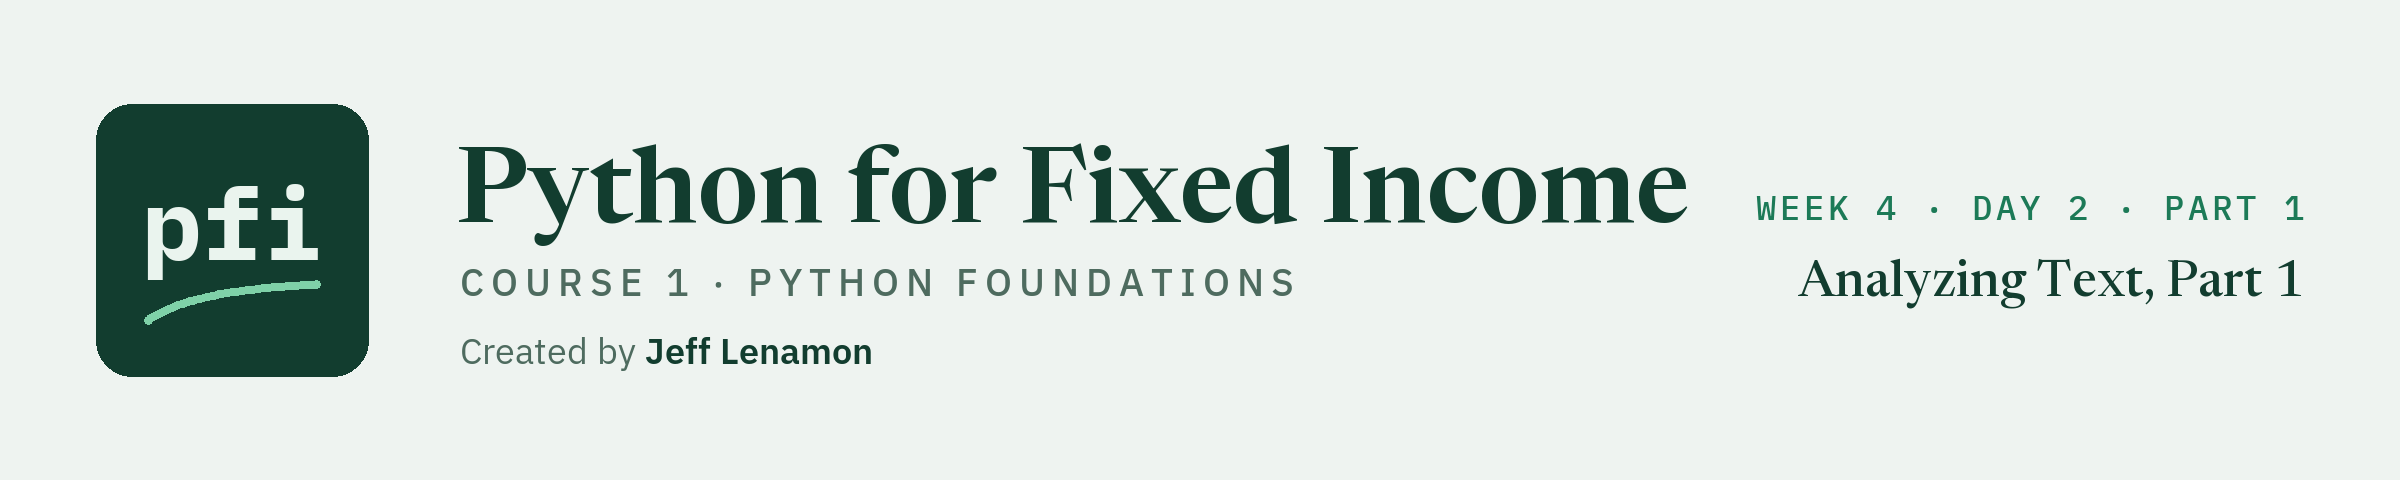

# Analyzing Text, Part 1

Week 4, Day 2, Part 1. Text is data too. Take one published statement as a Python string, pull figures out of it with patterns, and take a bond description apart.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2/17_analyzing_text.ipynb)

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


After each of its meetings, the Federal Open Market Committee publishes a short statement.

The credit desk keeps every one of them, and until now nobody has done anything with the file except read it.

The portfolio manager asks for a table, not an opinion: for each statement, how long it is, which figures it contains, how often a short list of words appears, and how much of its wording is shared with the statement before it.

You are the desk's analyst, and the job is to turn text into numbers that can be checked.

**What this notebook does and does not do.** It counts.

It reports that a word appears a number of times in the statement of a given date, or that a word count went from one number to another.

It does not say what a statement means, what the Committee did or will do, or why any wording changed.

It scores no tone and makes no forecast.

Reading policy is a different job, and it is not taught here.

Part 1 learns the tools on one statement.

Part 2 cleans the text, counts its words, and does the same work to all 46 statements.

The order of work in this part:

1. **Strings again.** The string tools from notebook 01, on one paragraph.
2. **Regular expressions.** A small language for describing patterns in text, used to pull out figures and names, to take a bond description apart, and to test the shape of an identifier.

**The data.** The text is real and public, and it is the only real data in this notebook.

The one use of portfolio data is a short list of bond descriptions and a column of identifiers, both from the course's synthetic holdings file.

Source: Board of Governors of the Federal Reserve System, Federal Open Market Committee statements, federalreserve.gov.

Each statement was downloaded from its own press release page, which is linked from the calendar page https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm.

Retrieved on 2026-10-03.

Span: the 46 statements from 2021-01-27 to 2026-09-16, which is every scheduled meeting of 2021 to 2025 and of 2026 up to the retrieval date.

Reuse: the Board's website says, at https://www.federalreserve.gov/disclaimer.htm, "Unless otherwise indicated, information on Board's website is in the public domain and may be copied and distributed without permission. Please cite to the Board as the source of the information."

The text in the file is exactly as published.

The only change made when the file was built was to white space: one space between words, and one line break between paragraphs.

When this notebook quotes a statement, it prints the words from the file and gives the statement's date.

## 17.1 Setting Up

Q. Import the libraries and check which versions are running.

In [2]:
# os is used to find the data folder, and re is Python's module for regular expressions
import os
import re

import pandas as pd

print('pandas version:', pd.__version__)

pandas version: 3.0.6


One name is new.

`re` comes with Python, so there is nothing to install.

This notebook was saved with the version printed above.

Yours may differ, and in Google Colab it may be older.

Q. Load the statements.

In [3]:
# on your own machine the file is in the repo's data folder. In Colab it is read from GitHub.
if os.path.exists('../../../data/fomc_statements.csv'):
    data_file = '../../../data/fomc_statements.csv'
else:
    data_file = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/fomc_statements.csv'

statements = pd.read_csv(data_file)

print('Rows and columns:', statements.shape)
print('First date:', statements['date'].min(), ' last date:', statements['date'].max())

statements.head(3)

Rows and columns: (46, 3)
First date: 2021-01-27  last date: 2026-09-16


,date,url,text
0,2021-01-27,https://www.federalreserve.gov/newsevents/pres...,The Federal Reserve is committed to using its ...
1,2021-03-17,https://www.federalreserve.gov/newsevents/pres...,The Federal Reserve is committed to using its ...
2,2021-04-28,https://www.federalreserve.gov/newsevents/pres...,The Federal Reserve is committed to using its ...


46 rows and 3 columns: the `date` of the statement, the `url` of its page, and the `text`.

The first statement is dated 2021-01-27 and the last 2026-09-16.

pandas shows only the start of each text, because a whole statement does not fit in a table cell.

Q. Is any text missing, and is any statement in the table twice?

In [4]:
# the empty cells in each column
print('Empty cells in each column:')
print(statements.isna().sum())

# every row is a different date and text, so no row should repeat
print('Repeated rows:', statements.duplicated().sum())

# every date and every text should appear once
print('Every date different:', statements['date'].is_unique, ' every text different:', statements['text'].is_unique)

Empty cells in each column:
date    0
url     0
text    0
dtype: int64
Repeated rows: 0
Every date different: True  every text different: True


Nothing is missing in any of the three columns, and no row, date, or text is repeated.

That is the first check on any table of text.

A repeated document would be counted twice in every count, and an empty one would have no words to count.

Q. Take one statement out of the table, to work on as a plain Python string.

In [5]:
# the row dated 2023-11-01, the text column, and the one value in it
statement = statements.loc[statements['date'] == '2023-11-01', 'text'].iloc[0]

print('Type:', type(statement))

# the paragraphs of a statement are separated by a line break, which Python writes as \n
paragraphs = statement.split('\n')
print('Paragraphs:', len(paragraphs))

# the first paragraph is the running example of the next section
opening = paragraphs[0]
print('Statement dated 2023-11-01, first paragraph:')
print(opening)

Type: <class 'str'>
Paragraphs: 5
Statement dated 2023-11-01, first paragraph:
Recent indicators suggest that economic activity expanded at a strong pace in the third quarter. Job gains have moderated since earlier in the year but remain strong, and the unemployment rate has remained low. Inflation remains elevated.


`statement` is a `str`, the same type as a ticker or an issuer name in notebook 01.

It is only longer.

`'\n'` is the line break character.

Splitting on it gives a list of 5 paragraphs.

`opening` is the first paragraph, three sentences long.

Every example in the next section uses it, so the numbers can be checked by eye.

## 17.2 Strings Again

Notebook 01 introduced strings.

A handful of string tools do a large share of all text work, and each has a twin in Excel.

For the Excel formulas in this section, suppose the paragraph is in cell A2.

Q. How long is the paragraph, in characters?

In [6]:
# len() counts every character: letters, spaces, and punctuation
print('Characters in the paragraph:', len(opening))
print('Characters in the whole statement:', len(statement))

Characters in the paragraph: 238
Characters in the whole statement: 2300


238 characters in the paragraph and 2,300 in the statement.

**Excel side by side.** `=LEN(A2)` returns 238.

Q. Write the paragraph in lower case, and in capitals.

In [7]:
# lower() and upper() return a new string. opening itself is not changed.
print(opening.lower())
print(opening.upper())

recent indicators suggest that economic activity expanded at a strong pace in the third quarter. job gains have moderated since earlier in the year but remain strong, and the unemployment rate has remained low. inflation remains elevated.
RECENT INDICATORS SUGGEST THAT ECONOMIC ACTIVITY EXPANDED AT A STRONG PACE IN THE THIRD QUARTER. JOB GAINS HAVE MODERATED SINCE EARLIER IN THE YEAR BUT REMAIN STRONG, AND THE UNEMPLOYMENT RATE HAS REMAINED LOW. INFLATION REMAINS ELEVATED.


**Excel side by side.** `=LOWER(A2)` and `=UPPER(A2)`.

A string method never changes the string it is called on.

It hands back a new one.

To keep the result, store it in a variable.

**Predict 1**

The last sentence of the paragraph is `Inflation remains elevated.`

```
'inflation' in opening
```

What does it return?

> A) `True`, because the word is in the paragraph.
>
> B) `False`.

Decide, then run the cell.

In [8]:
# in asks whether one string appears inside another
print("'inflation' in opening:", 'inflation' in opening)
print("'Inflation' in opening:", 'Inflation' in opening)

# the usual fix: put the text in lower case first, then look for the lower-case word
print("'inflation' in opening.lower():", 'inflation' in opening.lower())

'inflation' in opening: False
'Inflation' in opening: True
'inflation' in opening.lower(): True


The answer is B. Python compares characters, and `i` is not `I`.

The paragraph holds `Inflation` with a capital, so the lower-case word is not found.

Putting the text in lower case before searching is the usual fix.

**Excel side by side.** Excel has both behaviours, in two functions.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Is it there, capitals matter</td><td align="left"><code>'inflation' in opening</code></td><td align="left"><code>=ISNUMBER(FIND("inflation", A2))</code></td><td align="left">False</td></tr>
<tr><td align="left">Is it there, capitals ignored</td><td align="left"><code>'inflation' in opening.lower()</code></td><td align="left"><code>=ISNUMBER(SEARCH("inflation", A2))</code></td><td align="left">True</td></tr>
</table>
<br clear="left">

`FIND` tells capitals from lower case and `SEARCH` does not.

Both return the position of the text, or the error `#VALUE!` when it is not there, which is why `ISNUMBER` is wrapped around them.

Q. Where in the paragraph does `Inflation` start?

In [9]:
# find() returns the position of the first match. Python counts positions from 0.
position = opening.find('Inflation')
print('Position:', position)

# a slice takes the characters from one position up to, and not including, another
print('First 6 characters:', opening[:6])
print('9 characters from the position:', opening[position:position + 9])
print('Last 9 characters:', opening[-9:])

Position: 211
First 6 characters: Recent
9 characters from the position: Inflation
Last 9 characters: elevated.


`find()` returns 211.

Python counts from 0, so that is the 212th character.

**Excel side by side.** Slices do the work of three Excel functions.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Position of a word</td><td align="left"><code>opening.find('Inflation')</code></td><td align="left"><code>=FIND("Inflation", A2)</code></td><td align="left">211 in Python, 212 in Excel</td></tr>
<tr><td align="left">Characters from the left</td><td align="left"><code>opening[:6]</code></td><td align="left"><code>=LEFT(A2, 6)</code></td><td align="left">Recent</td></tr>
<tr><td align="left">Characters from the middle</td><td align="left"><code>opening[211:220]</code></td><td align="left"><code>=MID(A2, 212, 9)</code></td><td align="left">Inflation</td></tr>
<tr><td align="left">Characters from the right</td><td align="left"><code>opening[-9:]</code></td><td align="left"><code>=RIGHT(A2, 9)</code></td><td align="left">elevated.</td></tr>
</table>
<br clear="left">

Excel counts positions from 1 and Python from 0.

That one difference explains the 211 and the 212.

Q. How many times does `rate` appear in the paragraph?

In [10]:
# count() counts how many times a piece of text appears
print("count('rate'):", opening.count('rate'))
print("count('remain'):", opening.count('remain'))

count('rate'): 2
count('remain'): 3


`count('rate')` returns 2.

Read the paragraph: the word rate is there once, in `the unemployment rate`.

The second match is inside `moderated`.

`count('remain')` returns 3: `remain`, `remained`, and `remains`.

`count()` counts pieces of text, not words.

It does not know where a word starts or ends.

**Excel side by side.** Excel has no function that counts a word inside a cell, and the standard formula for it is built from two others.

Remove the word, and see how much shorter the text became:

`=(LEN(A2) - LEN(SUBSTITUTE(A2, "rate", ""))) / LEN("rate")`

It returns 2, the same answer as `count('rate')`, for the same reason: `SUBSTITUTE` also replaces `rate` inside `moderated`.

`SUBSTITUTE` tells capitals from lower case, as `count()` does.

Q. Split the paragraph into words. How many are there?

In [11]:
# split() with nothing in the brackets cuts the text at every run of white space
words = opening.split()

print('Words:', len(words))
print('First five:', words[:5])
print('Last three:', words[-3:])

Words: 37
First five: ['Recent', 'indicators', 'suggest', 'that', 'economic']
Last three: ['Inflation', 'remains', 'elevated.']


37 words.

`split()` returns a list, so everything notebook 01 said about lists applies: `len()`, positions, slices.

The last item is `'elevated.'` with its full stop attached.

`split()` cuts at spaces and nothing else.

Punctuation stays stuck to the word next to it.

Q. Join the first five words back into one string.

In [12]:
# join() is the reverse of split(). The string in front is what goes between the items.
print(' '.join(words[:5]))
print('-'.join(words[:5]))

Recent indicators suggest that economic
Recent-indicators-suggest-that-economic


`' '.join(...)` puts a space between the items, and `'-'.join(...)` puts a hyphen.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Split into words</td><td align="left"><code>opening.split()</code></td><td align="left"><code>=TEXTSPLIT(A2, " ")</code></td><td align="left">37 cells across a row</td></tr>
<tr><td align="left">Number of words</td><td align="left"><code>len(opening.split())</code></td><td align="left"><code>=COUNTA(TEXTSPLIT(A2, " "))</code></td><td align="left">37</td></tr>
<tr><td align="left">Number of words, any version</td><td align="left"></td><td align="left"><code>=LEN(TRIM(A2)) - LEN(SUBSTITUTE(TRIM(A2), " ", "")) + 1</code></td><td align="left">37</td></tr>
<tr><td align="left">Join with a separator</td><td align="left"><code>' '.join(words[:5])</code></td><td align="left"><code>=TEXTJOIN(" ", TRUE, B2:F2)</code></td><td align="left">Recent indicators suggest that economic</td></tr>
</table>
<br clear="left">

`TEXTSPLIT` is in Microsoft 365 and Excel 2024.

The third row works in every version: it counts the spaces and adds one.

On the Data tab, Text to Columns does the same split by hand, with Delimited and Space chosen.

Q. Split the paragraph into sentences at each full stop.

In [13]:
# split('.') cuts at every full stop, and the full stops themselves are dropped
pieces = opening.split('.')

# repr() prints a string with its quotes, so that spaces at the ends can be seen
for piece in pieces:
    print(repr(piece))

'Recent indicators suggest that economic activity expanded at a strong pace in the third quarter'
' Job gains have moderated since earlier in the year but remain strong, and the unemployment rate has remained low'
' Inflation remains elevated'
''


Four pieces.

The second and third start with a space, the one that followed the full stop.

The fourth is empty: it is what comes after the last full stop, which is nothing.

Q. Remove the spaces at the ends of each piece, and drop the empty one.

In [14]:
# strip() removes white space from both ends of a string
# the if at the end keeps a piece only when something is left after stripping
sentences = [piece.strip() for piece in pieces if piece.strip() != '']

for sentence in sentences:
    print(repr(sentence))
print('Sentences:', len(sentences))

'Recent indicators suggest that economic activity expanded at a strong pace in the third quarter'
'Job gains have moderated since earlier in the year but remain strong, and the unemployment rate has remained low'
'Inflation remains elevated'
Sentences: 3


3 sentences, with no stray spaces.

**Excel side by side.** `=TRIM(B2)`.

`TRIM` goes one step further than `strip()`: it also reduces any run of spaces inside the text to a single space.

`TRIM` removes only the ordinary space.

`strip()` also removes tabs, line breaks, and non-breaking spaces at the ends.

Splitting on a full stop is rough.

It would also cut `U.S.` into pieces.

It works on this paragraph because the only full stops in it end sentences.

Q. Replace one piece of text with another.

In [15]:
# replace() swaps every appearance of the first string for the second
print(sentences[2])
print(sentences[2].replace('Inflation', 'INFLATION'))

# replacing with an empty string removes the text
print(opening.replace('.', ''))

Inflation remains elevated
INFLATION remains elevated
Recent indicators suggest that economic activity expanded at a strong pace in the third quarter Job gains have moderated since earlier in the year but remain strong, and the unemployment rate has remained low Inflation remains elevated


`replace()` changed one word in the first call and removed all 3 full stops in the second.

**Excel side by side.** `=SUBSTITUTE(A2, ".", "")` for the formula, or Home, Find and Select, Replace (Ctrl+H) to change the cells in place.

The formula leaves the original in A2.

Replace overwrites it.

<table align="left">
<tr><th align="left">Tool</th><th align="left">What it does</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>len(text)</code></td><td align="left">number of characters</td><td align="left"><code>LEN</code></td></tr>
<tr><td align="left"><code>text.lower()</code>, <code>text.upper()</code></td><td align="left">change the case</td><td align="left"><code>LOWER</code>, <code>UPPER</code></td></tr>
<tr><td align="left"><code>'word' in text</code></td><td align="left">is it there</td><td align="left"><code>ISNUMBER(FIND(...))</code>, <code>ISNUMBER(SEARCH(...))</code></td></tr>
<tr><td align="left"><code>text.find('word')</code></td><td align="left">where it starts</td><td align="left"><code>FIND</code>, <code>SEARCH</code></td></tr>
<tr><td align="left"><code>text[a:b]</code></td><td align="left">a slice</td><td align="left"><code>LEFT</code>, <code>MID</code>, <code>RIGHT</code></td></tr>
<tr><td align="left"><code>text.count('word')</code></td><td align="left">how many times</td><td align="left"><code>LEN</code> less <code>LEN(SUBSTITUTE(...))</code></td></tr>
<tr><td align="left"><code>text.split()</code></td><td align="left">cut into a list</td><td align="left"><code>TEXTSPLIT</code>, Text to Columns</td></tr>
<tr><td align="left"><code>' '.join(items)</code></td><td align="left">glue a list together</td><td align="left"><code>TEXTJOIN</code></td></tr>
<tr><td align="left"><code>text.strip()</code></td><td align="left">remove spaces at the ends</td><td align="left"><code>TRIM</code></td></tr>
<tr><td align="left"><code>text.replace(old, new)</code></td><td align="left">swap text</td><td align="left"><code>SUBSTITUTE</code>, Find and Replace</td></tr>
</table>
<br clear="left">

These tools all look for one exact piece of text.

The next section looks for a pattern.

## 17.3 Regular Expressions

A statement gives its figures in its own style: `2 percent`, `5-1/4 to 5-1/2 percent`.

No single piece of text finds them all, because the digits differ each time.

What they share is a shape: some digits, then the word percent.

A **regular expression**, or regex, is a way to write down a shape.

Python's `re` module searches text for it.

Three functions cover most needs:

* `re.findall(pattern, text)` returns a list of every match;
* `re.search(pattern, text)` returns the first match, with its position;
* `re.sub(pattern, new, text)` replaces every match.

The examples use the third paragraph of the same statement.

Q. Print the first two sentences of the third paragraph.

In [16]:
# the third paragraph is at position 2 of the list
policy = paragraphs[2]

# this paragraph has no abbreviations, so a full stop and a space mark the end of a sentence
policy_sentences = policy.split('. ')

print('Statement dated 2023-11-01, third paragraph, first two sentences:')
print(policy_sentences[0] + '.')
print(policy_sentences[1] + '.')
print('Characters in the paragraph:', len(policy), ' sentences:', len(policy_sentences))

Statement dated 2023-11-01, third paragraph, first two sentences:
The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run.
In support of these goals, the Committee decided to maintain the target range for the federal funds rate at 5-1/4 to 5-1/2 percent.
Characters in the paragraph: 944  sentences: 6


Two figures can be seen: `2 percent` and `5-1/4 to 5-1/2 percent`.

The paragraph has 944 characters in 6 sentences, and the patterns below search all of it.

### Literal Matches

Q. Find every `percent` in the paragraph.

In [17]:
# the simplest pattern is plain text. It matches itself.
print(re.findall('percent', policy))
print('Matches:', len(re.findall('percent', policy)))

['percent', 'percent', 'percent', 'percent']
Matches: 4


4 matches.

A pattern of plain letters behaves like `count()`: it finds that exact text.

`findall()` returns the matches as a list, so `len()` counts them.

### Digits

Q. Find every digit in the paragraph.

In [18]:
# \d stands for any one digit, 0 to 9
print(re.findall(r'\d', policy))

# \d+ stands for one or more digits in a row
print(re.findall(r'\d+', policy))

['2', '5', '1', '4', '5', '1', '2', '2', '2']
['2', '5', '1', '4', '5', '1', '2', '2', '2']


9 digits.

Both lines return the same list here, because no figure in this paragraph has two digits in a row.

In Python, `\d` also matches the digits of other writing systems.

The statements hold only 0 to 9, so it makes no difference here.

The `r` in front of the quotes makes a **raw string**.

In an ordinary string Python treats a backslash as the start of a special character, as in `'\n'`.

In a raw string a backslash is only a backslash, which is what a regex needs.

Write every pattern as `r'...'`.

<table align="left">
<tr><th align="left">Piece</th><th align="left">Meaning</th></tr>
<tr><td align="left"><code>\d</code></td><td align="left">any one digit</td></tr>
<tr><td align="left"><code>+</code></td><td align="left">one or more of whatever is just before it</td></tr>
<tr><td align="left"><code>\d+</code></td><td align="left">a run of digits, as long as it goes</td></tr>
</table>
<br clear="left">

**Predict 2**

The first two sentences show `2 percent` once.

Read to the end of the paragraph and it appears 3 times in all.

```
re.findall(r'\d+ percent', policy)
```

How many matches does it return?

> A) 3, the three appearances of `2 percent`.
>
> B) 4.
>
> C) 5.

Decide, then run the cell.

In [19]:
# one or more digits, a space, and the word percent
print(re.findall(r'\d+ percent', policy))
print('Matches:', len(re.findall(r'\d+ percent', policy)))

['2 percent', '2 percent', '2 percent', '2 percent']
Matches: 4


The answer is B. 4 matches, and every one reads `2 percent`.

One of them is not a 2 percent figure at all.

It is the tail of `5-1/2 percent`: a digit, a space, and the word percent.

The pattern **matched too much**.

It did what it was told.

Nothing in `\d+ percent` says what may or may not come before the digits.

Counting matches without looking at them would have reported 4 where the text has 3.

Print what a pattern matches before trusting how many.

### Character Classes

The fix is to describe the whole figure, so that `5-1/2` is taken as one piece.

Q. Find every figure made of digits, hyphens, and slashes that is followed by `percent`.

In [20]:
# square brackets list the characters allowed at one position
# [\d/-] is one character that is a digit, a slash, or a hyphen, and the + repeats it
figures = re.findall(r'[\d/-]+ percent', policy)
print(figures)

# now the count of the 2 percent figure is a count of whole figures
print("Figures that are exactly '2 percent':", figures.count('2 percent'))

['2 percent', '5-1/2 percent', '2 percent', '2 percent']
Figures that are exactly '2 percent': 3


4 figures: `2 percent`, `5-1/2 percent`, and `2 percent` twice more.

3 of them are exactly `2 percent`, which matches the text.

<table align="left">
<tr><th align="left">Piece</th><th align="left">Meaning</th></tr>
<tr><td align="left"><code>[abc]</code></td><td align="left">one character: an a, a b, or a c</td></tr>
<tr><td align="left"><code>[a-z]</code></td><td align="left">one lower-case letter. Between two characters a hyphen means a range.</td></tr>
<tr><td align="left"><code>[A-Z]</code></td><td align="left">one capital letter</td></tr>
<tr><td align="left"><code>[\d/-]</code></td><td align="left">one digit, slash, or hyphen. A hyphen at the end of the brackets is a plain hyphen.</td></tr>
<tr><td align="left"><code>[^abc]</code></td><td align="left">one character that is not an a, a b, or a c. The <code>^</code> at the start means not.</td></tr>
</table>
<br clear="left">

Q. Find the range, written as the statement writes it.

In [21]:
# a figure, the word to with a space on each side, a figure, a space, and percent
range_pattern = r'[\d/-]+ to [\d/-]+ percent'
print(re.findall(range_pattern, policy))

['5-1/4 to 5-1/2 percent']


One match: `5-1/4 to 5-1/2 percent`.

<table align="left">
<tr><th align="left">Piece of <code>[\d/-]+ to [\d/-]+ percent</code></th><th align="left">Meaning</th></tr>
<tr><td align="left"><code>[\d/-]+</code></td><td align="left">the first figure: digits, slashes, and hyphens</td></tr>
<tr><td align="left"><code> to </code></td><td align="left">a space, the letters t and o, a space</td></tr>
<tr><td align="left"><code>[\d/-]+</code></td><td align="left">the second figure</td></tr>
<tr><td align="left"><code> percent</code></td><td align="left">a space and the word</td></tr>
</table>
<br clear="left">

### Groups and Search

Q. Pull the two ends of the range out separately.

In [22]:
# round brackets mark a group. With groups in the pattern, findall() returns the groups.
print(re.findall(r'([\d/-]+) to ([\d/-]+) percent', policy))

# search() returns the first match as an object that can be asked questions
match = re.search(r'([\d/-]+) to ([\d/-]+) percent', policy)
print('Whole match:', match.group(0))
print('First group:', match.group(1))
print('Second group:', match.group(2))
print('Starts at position:', match.start())

[('5-1/4', '5-1/2')]
Whole match: 5-1/4 to 5-1/2 percent
First group: 5-1/4
Second group: 5-1/2
Starts at position: 218


The groups are `5-1/4` and `5-1/2`.

`group(0)` is the whole match, and `group(1)` and `group(2)` are the pieces inside the first and second pair of round brackets.

The match starts at position 218 of the paragraph.

The two ends are still text.

Turning `5-1/4` into the number 5.25 is arithmetic on the pieces: 5 plus 1 divided by 4.

Q. Search the paragraph for a figure in basis points.

In [23]:
# the first figure followed by the words basis points
re.search(r'\d+ basis points', policy).group(0)

AttributeError: 'NoneType' object has no attribute 'group'

An `AttributeError`, and the last line reads `'NoneType' object has no attribute 'group'`.

The paragraph has no figure in basis points.

When `search()` finds nothing it returns `None`, Python's value for nothing, and `None` has no `group()`.

The pattern was fine.

The code assumed a match.

`findall()` does not have this problem, because no matches is an empty list.

With `search()`, test the result before using it.

Q. Do the search again, and handle the case of no match.

In [24]:
match = re.search(r'\d+ basis points', policy)

# None means the pattern was not found
if match is None:
    print('No figure in basis points in this paragraph.')
else:
    print(match.group(0))

No figure in basis points in this paragraph.


The code now says in words that nothing was found.

### Replacing With a Pattern

Q. Replace the range in the second sentence with a marker.

In [25]:
# the sentence that holds the range, with its full stop put back
sentence = policy_sentences[1] + '.'
print(sentence)

# sub() takes the pattern, the replacement, and the text
print(re.sub(range_pattern, '[RANGE]', sentence))

In support of these goals, the Committee decided to maintain the target range for the federal funds rate at 5-1/4 to 5-1/2 percent.
In support of these goals, the Committee decided to maintain the target range for the federal funds rate at [RANGE].


`re.sub()` is `replace()` with a pattern in place of fixed text.

It would replace any range written in this style, whatever its digits.

### Words and Their Edges

Section 17.2 counted `rate` twice in the first paragraph, once inside `moderated`.

**Predict 3**

`statement.count('rate')` returns 4 for the whole statement of 2023-11-01.

A pattern can ask for `rate` as a whole word.

```
re.findall(r'\brate\b', statement)
```

How many matches?

> A) 4, the same as `count()`.
>
> B) 3.
>
> C) 0, because of the backslashes.

Decide, then run the cell.

In [26]:
print("count('rate'):", statement.count('rate'))

# \w is one word character: a letter, a digit, or an underscore. * means none or more.
# so \w*rate\w* is rate with any letters attached in front or behind
print(re.findall(r'\w*rate\w*', statement))

# \b is a word boundary: the edge between a word character and anything else
print(re.findall(r'\brate\b', statement))
print('Whole word rate:', len(re.findall(r'\brate\b', statement)))

count('rate'): 4
['moderated', 'rate', 'rate', 'rate']
['rate', 'rate', 'rate']
Whole word rate: 3


The answer is B. The word `rate` appears 3 times.

The fourth match of `count()` was `moderated`, as the middle line shows.

`\b` matches no character.

It matches a position: the place where a word starts or ends.

`\brate\b` is `rate` with a word edge on both sides.

**The word rate appears 3 times in the statement dated 2023-11-01.** Keep that number.

<table align="left">
<tr><th align="left">Piece</th><th align="left">Meaning</th></tr>
<tr><td align="left"><code>\w</code></td><td align="left">one word character: a letter, a digit, or an underscore</td></tr>
<tr><td align="left"><code>\s</code></td><td align="left">one white space character: a space, a tab, or a line break</td></tr>
<tr><td align="left"><code>\b</code></td><td align="left">the edge of a word</td></tr>
<tr><td align="left"><code>*</code></td><td align="left">none or more of whatever is just before it</td></tr>
<tr><td align="left"><code>+</code></td><td align="left">one or more</td></tr>
<tr><td align="left"><code>?</code></td><td align="left">none or one, which makes a piece optional</td></tr>
<tr><td align="left"><code>{4}</code></td><td align="left">exactly 4</td></tr>
<tr><td align="left"><code>.</code></td><td align="left">any one character. To match a real full stop, write <code>\.</code></td></tr>
</table>
<br clear="left">

### Anchors

Q. What is the first word of the statement, and of each paragraph?

In [27]:
# ^ anchors the pattern to the start of the text
print(re.findall(r'^\w+', statement))

# with re.MULTILINE, ^ also matches at the start of every line
print(re.findall(r'^\w+', statement, re.MULTILINE))

# $ anchors the pattern to the end of a line. \. is a real full stop.
print(re.findall(r'\w+\.$', statement, re.MULTILINE))

['Recent']
['Recent', 'The', 'The', 'In', 'Voting']
['elevated.', 'risks.', 'objective.', 'developments.', 'Waller.']


The statement starts with `Recent`.

Its five paragraphs start with `Recent`, `The`, `The`, `In`, and `Voting`, and end with `elevated.`, `risks.`, `objective.`, `developments.`, and `Waller.`

`^` and `$` are called **anchors**.

They tie a pattern to the start or the end, so it cannot match in the middle.

Anchors are how a pattern checks a whole value.

The `date` column should hold dates as four digits, two digits, and two digits.

Q. Does a value have the shape of a date? And what date is in the page address?

In [28]:
# from start to end: 4 digits, a hyphen, 2 digits, a hyphen, 2 digits
date_pattern = r'^\d{4}-\d{2}-\d{2}$'

print('2023-11-01:', re.search(date_pattern, '2023-11-01') is not None)
print('2023-11-1:', re.search(date_pattern, '2023-11-1') is not None)
print('11/01/2023:', re.search(date_pattern, '11/01/2023') is not None)

# the address of the statement's page holds the date as 8 digits in a row
url = statements.loc[statements['date'] == '2023-11-01', 'url'].iloc[0]
print(url)

# three groups: the year, the month, and the day
print(re.search(r'(\d{4})(\d{2})(\d{2})', url).groups())

2023-11-01: True
2023-11-1: False
11/01/2023: False
https://www.federalreserve.gov/newsevents/pressreleases/monetary20231101a.htm
('2023', '11', '01')


Only `2023-11-01` has the shape.

`2023-11-1` has a one-digit day and `11/01/2023` has slashes.

One quirk: `$` also matches just before a line break at the very end of the text, so the same value with a line break after it would pass too.

The pattern checks the shape and nothing more.

It would accept `2023-99-99`.

Whether a value is a real date is a job for `pd.to_datetime()`, from notebook 13.

From the address, the three groups are `2023`, `11`, and `01`, which agree with the `date` column.

### Names

The last paragraph of the statement lists who voted.

Q. Pull the names out of the voting paragraph.

In [29]:
# the last paragraph of the statement
voting = paragraphs[-1]
print('Statement dated 2023-11-01, last paragraph:')
print(voting)

# the names are separated by semicolons, so the number of names is one more than the number of semicolons
print('Names, counted by semicolons:', voting.count(';') + 1)

# a first name, a middle initial with a full stop, and a last name
names = re.findall(r'[A-Z][a-z]+ [A-Z]\. [A-Z][a-z]+', voting)
print(names)
print('Names matched:', len(names))

Statement dated 2023-11-01, last paragraph:
Voting for the monetary policy action were Jerome H. Powell, Chair; John C. Williams, Vice Chair; Michael S. Barr; Michelle W. Bowman; Lisa D. Cook; Austan D. Goolsbee; Patrick Harker; Philip N. Jefferson; Neel Kashkari; Adriana D. Kugler; Lorie K. Logan; and Christopher J. Waller.
Names, counted by semicolons: 12
['Jerome H. Powell', 'John C. Williams', 'Michael S. Barr', 'Michelle W. Bowman', 'Lisa D. Cook', 'Austan D. Goolsbee', 'Philip N. Jefferson', 'Adriana D. Kugler', 'Lorie K. Logan', 'Christopher J. Waller']
Names matched: 10


The paragraph lists 12 names, counted by the semicolons between them.

The pattern matched 10.

This time the pattern **matched too little**.

Two of the names are written without a middle initial, and the pattern insists on one.

<table align="left">
<tr><th align="left">Piece of <code>[A-Z][a-z]+ [A-Z]\. [A-Z][a-z]+</code></th><th align="left">Meaning</th></tr>
<tr><td align="left"><code>[A-Z][a-z]+</code></td><td align="left">a capital letter and then one or more lower-case letters: a first name</td></tr>
<tr><td align="left"><code> [A-Z]\. </code></td><td align="left">a space, a capital, a real full stop, a space: the middle initial</td></tr>
<tr><td align="left"><code>[A-Z][a-z]+</code></td><td align="left">the last name</td></tr>
</table>
<br clear="left">

Q. Make the middle initial optional.

In [30]:
# (?: ... ) is a group that findall() does not return by itself, and the ? after it makes it optional
names = re.findall(r'[A-Z][a-z]+ (?:[A-Z]\. )?[A-Z][a-z]+', voting)
print(names)
print('Names matched:', len(names))

['Jerome H. Powell', 'John C. Williams', 'Vice Chair', 'Michael S. Barr', 'Michelle W. Bowman', 'Lisa D. Cook', 'Austan D. Goolsbee', 'Patrick Harker', 'Philip N. Jefferson', 'Neel Kashkari', 'Adriana D. Kugler', 'Lorie K. Logan', 'Christopher J. Waller']
Names matched: 13


13 matches, one more than the 12 names.

The extra one is `Vice Chair`: two words that each start with a capital, which is all the looser pattern asks for.

Tightening a pattern loses real matches and loosening it lets false ones in.

The count from the semicolons, 12, is what shows which way the pattern is wrong.

Q. Drop the match that is not a name.

In [31]:
# keep every match except the title
names = [name for name in names if name != 'Vice Chair']
print(names)
print('Names:', len(names))

['Jerome H. Powell', 'John C. Williams', 'Michael S. Barr', 'Michelle W. Bowman', 'Lisa D. Cook', 'Austan D. Goolsbee', 'Patrick Harker', 'Philip N. Jefferson', 'Neel Kashkari', 'Adriana D. Kugler', 'Lorie K. Logan', 'Christopher J. Waller']
Names: 12


12 names, the same as the count by semicolons.

The pattern is written for the names in this paragraph.

A name with a hyphen, an accent, or three parts would need a wider pattern.

A regex is always tested against a count that came from somewhere else.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Does the text contain the pattern?</td><td align="left"><code>re.search(pattern, text) is not None</code></td><td align="left"><code>=REGEXTEST(A2, pattern)</code></td></tr>
<tr><td align="left">Pull out the first match</td><td align="left"><code>re.search(pattern, text).group(0)</code></td><td align="left"><code>=REGEXEXTRACT(A2, pattern)</code></td></tr>
<tr><td align="left">Replace every match</td><td align="left"><code>re.sub(pattern, new, text)</code></td><td align="left"><code>=REGEXREPLACE(A2, pattern, new)</code></td></tr>
<tr><td align="left">Text between two markers</td><td align="left"><code>re.search(r' at (.+) percent', text).group(1)</code></td><td align="left"><code>=TEXTBEFORE(TEXTAFTER(A2, " at "), " percent")</code></td></tr>
<tr><td align="left">Count cells that contain a piece of text</td><td align="left">a loop over the cells</td><td align="left"><code>=COUNTIF(B2:B38, "*rate*")</code></td></tr>
</table>
<br clear="left">

`REGEXTEST`, `REGEXEXTRACT`, and `REGEXREPLACE` are in Excel for Microsoft 365.

Earlier versions do not have them.

With the second sentence of the third paragraph in A2, `=REGEXEXTRACT(A2, "[\d/-]+ to [\d/-]+ percent")` returns `5-1/4 to 5-1/2 percent`.

`TEXTBEFORE` and `TEXTAFTER`, in Microsoft 365 and Excel 2024, cut text at a marker.

On the same sentence the formula in the table returns `5-1/4 to 5-1/2`, and so does the Python line beside it.

That Python line is for one sentence.

`.+` takes as much as it can, so on the whole third paragraph it starts at the first ` at ` and runs on to the last ` percent`, across four sentences.

Every version of Excel has **wildcards** in `COUNTIF`, `SUMIF`, `SEARCH`, and the Find box: `*` stands for any run of characters and `?` for any one character.

With the 37 words of the first paragraph in B2:B38, `=COUNTIF(B2:B38, "*rate*")` returns 2, the cells `moderated` and `rate`, and `=COUNTIF(B2:B38, "rate")` returns 1.

**Flash Fill** (Data, Flash Fill, or Ctrl+E) learns a pattern from examples.

Type the range from the first row into the next column, start the second, and Excel fills the rest in the same way.

It gives values, not a formula, so check the rows it filled.

### Greedy and Lazy

The table above put `.+` between two markers, and it worked on one sentence.

`+` and `*` are **greedy**: they take as much text as they can.

A `?` straight after one of them makes it **lazy**: it takes as little as it can.

Q. Take the text between ` at ` and ` percent` from the whole third paragraph, first with the greedy `.+` and then with the lazy `.+?`.

In [32]:
# greedy: .+ runs on to the last ' percent' in the paragraph
greedy = re.search(r' at (.+) percent', policy).group(1)
print(f'Greedy: {len(greedy):,} of the {len(policy):,} characters in the paragraph')
print(f'  it starts: {greedy[:40]}')
print(f'  it ends:   {greedy[-40:]}')

# lazy: .+? stops at the first ' percent' it can reach
lazy = re.search(r' at (.+?) percent', policy).group(1)
print(f'Lazy: {len(lazy):,} characters: {lazy}')

# findall() with the lazy pattern returns every short piece
print(re.findall(r' at (.+?) percent', policy))

Greedy: 858 of the 944 characters in the paragraph
  it starts: the rate of 2 percent over the longer ru
  it ends:   ommitted to returning inflation to its 2
Lazy: 13 characters: the rate of 2
['the rate of 2', '5-1/4 to 5-1/2']


Greedy took 858 of the 944 characters, from the first ` at ` to the last ` percent` in the paragraph.

Lazy took 13: `the rate of 2`.

With the lazy pattern `findall()` returns two pieces, `the rate of 2` and `5-1/4 to 5-1/2`.

Each one stops at the first ` percent` after its ` at `.

Both patterns ran without an error, and each did what it says.

Only the printed match shows which one was written.

`.*` and `.*?` differ in the same way.

A pattern that describes the figure itself is tighter than either.

`[\d/-]+ to [\d/-]+ percent`, from earlier in this section, cannot run on, because a letter is not in its brackets.

<table align="left">
<tr><th align="left">Piece</th><th align="left">Meaning</th></tr>
<tr><td align="left"><code>.+</code> and <code>.*</code></td><td align="left">greedy: any characters, as many as possible</td></tr>
<tr><td align="left"><code>.+?</code> and <code>.*?</code></td><td align="left">lazy: any characters, as few as possible</td></tr>
</table>
<br clear="left">

**Excel side by side.** `=TEXTBEFORE(TEXTAFTER(A2, " at "), " percent")` cuts at the first marker it finds each time.

With the whole third paragraph in A2 it returns `the rate of 2`, the same as the lazy pattern.

### Testing a Whole Value

The date check under Anchors needed `^` and `$`, and `$` had a quirk.

`re.fullmatch()` is built for the job: it succeeds only when the pattern covers the whole value, from the first character to the last, and it needs no anchors.

Q. Test three values against the shape of a date, with `search()` and the anchors, and with `fullmatch()`.

In [33]:
# the shape of a date, with no anchors
date_shape = r'\d{4}-\d{2}-\d{2}'

# the second value ends in a line break, and the third has a word in front. repr() shows the line break as \n.
for value in ['2023-11-01', '2023-11-01\n', 'on 2023-11-01']:
    anchored = re.search(date_pattern, value) is not None
    whole = re.fullmatch(date_shape, value) is not None
    print(f'{repr(value)}   search with ^ and $: {anchored}   fullmatch: {whole}')

'2023-11-01'   search with ^ and $: True   fullmatch: True
'2023-11-01\n'   search with ^ and $: True   fullmatch: False
'on 2023-11-01'   search with ^ and $: False   fullmatch: False


`2023-11-01` passes both tests, and `on 2023-11-01` fails both.

The value with a line break at its end passes `search()` with `^` and `$` and fails `fullmatch()`.

That is the quirk of `$`, and `fullmatch()` does not have it.

To test a whole value, use `re.fullmatch()`.

For a whole column, pandas has `.str.fullmatch()`, which is used below.

**Excel side by side.** `REGEXTEST` looks for the pattern in any part of the text, so in Excel a test of a whole value needs the anchors: `=REGEXTEST(A2, "^\d{4}-\d{2}-\d{2}$")`.

As above, it is in Excel for Microsoft 365.

### Bond Descriptions

A bond often arrives as one piece of text: a ticker, a coupon, and a maturity.

A pattern with three groups takes it apart.

The eight descriptions below were typed from rows of the course's synthetic holdings file.

The issuers are invented.

Q. Pull the ticker, the coupon, and the maturity out of the first description.

In [34]:
# eight descriptions, typed by hand: ticker, coupon in percent, maturity as month/day/year
descriptions = [
    'KRIX 7.875 08/26/2032',
    'BEZE 7 06/18/2032',
    'BEZH 8.125 04/17/2029',
    'BEZL 5.125 06/03/2030',
    'LORE 7.25 03/08/2030',
    'OSTV  6.5 04/01/2033',
    'SYLX 3.625 09/03/2055',
    'VYRN 7.375 12/12/2037',
]

# three groups: capital letters, digits with a decimal point, and a date written with slashes
first_pattern = r'([A-Z]+) (\d+\.\d+) (\d{2}/\d{2}/\d{4})'

# fullmatch(), because the pattern should account for the whole description
match = re.fullmatch(first_pattern, descriptions[0])
print(match.groups())

('KRIX', '7.875', '08/26/2032')


Three groups: `KRIX`, `7.875`, and `08/26/2032`.

All three are text, the coupon included.

<table align="left">
<tr><th align="left">Piece of the pattern</th><th align="left">Meaning</th></tr>
<tr><td align="left"><code>([A-Z]+)</code></td><td align="left">the ticker: one or more capital letters</td></tr>
<tr><td align="left"><code>(\d+\.\d+)</code></td><td align="left">the coupon: digits, a real full stop, digits</td></tr>
<tr><td align="left"><code>(\d{2}/\d{2}/\d{4})</code></td><td align="left">the maturity: two digits, a slash, two digits, a slash, four digits</td></tr>
</table>
<br clear="left">

Q. Run the pattern on all eight descriptions. How many does it read?

In [35]:
# fullmatch() returns None for a description the pattern cannot read
not_read = [text for text in descriptions if re.fullmatch(first_pattern, text) is None]

print(f'Read: {len(descriptions) - len(not_read):,} of {len(descriptions):,}')
print('Not read:', not_read)

Read: 6 of 8
Not read: ['BEZE 7 06/18/2032', 'OSTV  6.5 04/01/2033']


6 of 8.

The pattern **matched too little**, as the first pattern for the names did.

`BEZE 7 06/18/2032` has a coupon with no decimal point, and the pattern insists on one.

The `OSTV` line has two spaces after the ticker, as the printed list shows, and the pattern allows one.

The count caught it: eight descriptions in, six read.

Neither failure raised an error.

Q. Widen the pattern, and build a table with the coupon as a number and the maturity as a date.

In [36]:
# \s+ is one or more spaces, and (?:\.\d+)? makes the decimal part of the coupon optional
description_pattern = r'([A-Z]+)\s+(\d+(?:\.\d+)?)\s+(\d{2}/\d{2}/\d{4})'

rows = []
for text in descriptions:
    match = re.fullmatch(description_pattern, text)
    # a check that matters is an assert: a description that cannot be read stops the run, with its text in the message
    assert match is not None, f'cannot read this description: {text}'
    # float() turns the coupon text into a number
    rows.append({'ticker': match.group(1), 'coupon': float(match.group(2)), 'maturity': match.group(3)})

bonds = pd.DataFrame(rows)

# the maturity text is month/day/year, and format= says so
bonds['maturity'] = pd.to_datetime(bonds['maturity'], format='%m/%d/%Y')
print(bonds)

mean_coupon = bonds['coupon'].mean()
latest = bonds['maturity'].max().date()
print(f'Read: {len(bonds):,} of {len(descriptions):,}   mean coupon: {mean_coupon:.3f} percent   latest maturity: {latest}')

  ticker  coupon   maturity
0   KRIX   7.875 2032-08-26
1   BEZE   7.000 2032-06-18
2   BEZH   8.125 2029-04-17
3   BEZL   5.125 2030-06-03
4   LORE   7.250 2030-03-08
5   OSTV   6.500 2033-04-01
6   SYLX   3.625 2055-09-03
7   VYRN   7.375 2037-12-12
Read: 8 of 8   mean coupon: 6.609 percent   latest maturity: 2055-09-03


All 8 are read.

The coupons are numbers now, so they can be averaged: 6.609 percent.

The maturities are dates, and the latest is 2055-09-03.

The `assert` passed in silence.

Had one description not matched, the run would have stopped at that line with the text in the message, and no table one row short would have been printed.

The pattern is written for these eight.

A coupon typed as a fraction, a two-digit year, or a ticker in lower case would each need a wider pattern, and the `assert` is what would say so.

**Excel side by side.** With a description in A2, `=TEXTSPLIT(TRIM(A2), " ")` in B2 spills the three pieces into B2, C2, and D2.

`TRIM` reduces the double space to one first.

The pieces are text, and `=VALUE(C2)` gives the coupon as a number.

`TEXTSPLIT` is in Microsoft 365 and Excel 2024.

In Excel for Microsoft 365, `=REGEXEXTRACT(A2, pattern, 2)` returns the groups of the first match in the same way, one cell for each group.

### The Shape of a CUSIP

A CUSIP is nine characters.

The CUSIPs of the course's holdings file are invented, and each of the nine is a digit or a capital letter.

A pattern can test that shape on a whole column.

Q. Does every CUSIP in the holdings file have that shape?

In [37]:
# the synthetic holdings file of weeks 2 and 3. In Colab it is read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    holdings_file = '../../../data/holdings.csv'
else:
    holdings_file = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

# dtype=str reads the identifier as text
cusips = pd.read_csv(holdings_file, dtype={'cusip': str})['cusip']

# nine characters, each a digit or a capital letter. .str.fullmatch() tests every value in the column.
cusip_shape = r'[0-9A-Z]{9}'
has_shape = cusips.str.fullmatch(cusip_shape)
print(f'CUSIPs tested: {len(cusips):,}   with the shape: {has_shape.sum():,}')

# a check that matters is an assert: stop here if any identifier is malformed
assert has_shape.all(), 'at least one CUSIP does not have nine digits or capital letters'

# the first CUSIP of the file, and four damaged copies of it typed by hand
for value in [cusips.iloc[0], '99080cae8', '99080CAE', '99080CAE8 ', '99080-CAE8']:
    print(f'{repr(value)}   has the shape: {re.fullmatch(cusip_shape, value) is not None}')

CUSIPs tested: 200   with the shape: 200
'99080CAE8'   has the shape: True
'99080cae8'   has the shape: False
'99080CAE'   has the shape: False
'99080CAE8 '   has the shape: False
'99080-CAE8'   has the shape: False


All 200 CUSIPs in the file have the shape, and the `assert` passed.

The four damaged copies fail: letters in lower case, eight characters, a space at the end, and a hyphen in the middle.

The space at the end is the one the eye misses, and `repr()` shows it inside the quotes.

The class is `[0-9A-Z]` and not `\d`, because `\d` also matches the digits of other writing systems.

This is a test of shape only, like the date pattern.

The ninth character of a CUSIP is a check digit worked out from the first eight, and the pattern does not test it.

**Excel side by side.** With a CUSIP in B2, `=REGEXTEST(B2, "^[0-9A-Z]{9}$")` is the same test, in Excel for Microsoft 365.

In every version, `=LEN(B2)=9` tests the length, and `=EXACT(B2, UPPER(B2))` tests that no letter is in lower case.

## You Can Now

By the end of this notebook, you can:

* Measure, search, slice, split, join, strip, and replace text with string methods.
* Write a regular expression from pieces: `\d`, `\w`, `\s`, `\b`, character classes, `+`, `*`, `?`, `{n}`, anchors, and groups.
* Use `re.findall()`, `re.search()`, and `re.sub()`, and handle a search that finds nothing.
* Test a pattern against a count from somewhere else, and fix one that matches too much or too little.
* Tell a greedy pattern from a lazy one, and test a whole value with `re.fullmatch()` and `.str.fullmatch()`.
* Take a bond description apart into ticker, coupon, and maturity, and test the shape of a CUSIP.
* Match each step to Excel: `LEN`, `LOWER`, `UPPER`, `TRIM`, `FIND`, `SEARCH`, `LEFT`, `MID`, `RIGHT`, `SUBSTITUTE`, `TEXTSPLIT`, `TEXTJOIN`, `COUNTIF` with wildcards, `REGEXTEST`, `REGEXEXTRACT`, `REGEXREPLACE`, Find and Replace, and Flash Fill.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Exercises 1 and 2 use a second statement, the one dated 2022-09-21, stored as `other`.

Exercises 3 to 6 use bond descriptions and identifiers typed from the course's synthetic holdings file, and exercise 6 asks you to write a function.

The AI check, exercise 7, uses the eight descriptions of the lesson.

Every answer is a count, a figure, or a piece of text taken from a file.

None is a reading of what a statement means.

Replace each `...` with your own code, then run the check cell.

Print the numbers you rely on.

Run the next cell first.

It imports the libraries, defines `check`, a small function that marks your answers, and loads a fresh `statements`.

It prints the shape of the table, (46, 3), and the type of `other`.

In [38]:
import os
import re

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# a fresh copy of the statements. In Colab the file is read from GitHub.
if os.path.exists('../../../data/fomc_statements.csv'):
    data_file = '../../../data/fomc_statements.csv'
else:
    data_file = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/fomc_statements.csv'

statements = pd.read_csv(data_file)

# the statement the first two exercises use
other = statements.loc[statements['date'] == '2022-09-21', 'text'].iloc[0]

print(statements.shape)
print(type(other))

(46, 3)
<class 'str'>


### Exercise 1

Q. For the statement dated 2022-09-21, `other`: how many characters does it have, how many words by `split()`, and how many times does `inflation` appear when capitals are ignored? Store the answers in **ex1_characters**, **ex1_words**, and **ex1_inflation**.

In [39]:
ex1_characters = ...
ex1_words = ...
ex1_inflation = ...

In [40]:
check('Exercise 1 characters', ex1_characters, 2066)
check('Exercise 1 words', ex1_words, 314)
check('Exercise 1 inflation', ex1_inflation, 7)

Exercise 1 characters: not attempted yet
Exercise 1 words: not attempted yet
Exercise 1 inflation: not attempted yet


### Exercise 2

Q. With regular expressions, on `other`: find the range written as `... to ... percent` and store the list that `re.findall()` returns in **ex2_range**. Use groups to take the two ends, and turn the upper end into a number: `3-1/4` is 3 plus 1 divided by 4. Store it in **ex2_upper**. Then count the names in the last paragraph and store the count in **ex2_names**.

In [41]:
ex2_range = ...
ex2_upper = ...
ex2_names = ...

In [42]:
check('Exercise 2 range', ex2_range, ['3 to 3-1/4 percent'])
check('Exercise 2 upper end', ex2_upper, 3.25)
check('Exercise 2 names', ex2_names, 12)

Exercise 2 range: not attempted yet
Exercise 2 upper end: not attempted yet
Exercise 2 names: not attempted yet


### Exercise 3

Exercises 3 to 6 use two short lists typed from rows of the course's synthetic holdings file.

Run the next cell to create them: six bond descriptions in `more_descriptions`, and nine identifiers in `identifiers`, some of them damaged on purpose.

In [43]:
# six descriptions, typed by hand: ticker, coupon in percent, maturity as month/day/year
more_descriptions = [
    'KRIX 6.625 05/09/2033',
    'BEZL 6.125 04/09/2053',
    'ZEPN 5 08/16/2036',
    'GALX  9.25 06/17/2038',
    'TROE 4.375 12/26/2027',
    'LORE 8.625 06/09/2032',
]

# nine identifiers, typed by hand
identifiers = ['99087JAG1', '99039NAG1', '99138IAF4', '99088kah5', '99093PAA', '99114KAB6 ', '99053-BAG8', '99057FAC4', '99005FAA1']

print(f'Descriptions: {len(more_descriptions):,}   identifiers: {len(identifiers):,}')

Descriptions: 6   identifiers: 9


Q. Pull the coupon out of each of the six descriptions with a group, and turn it into a number. Store the list of six numbers, in the order of the descriptions, in **ex3_coupons**, and the highest coupon in **ex3_highest**. Look at the descriptions first: one coupon has no decimal point, and one line has two spaces.

In [44]:
ex3_coupons = ...
ex3_highest = ...

In [45]:
check('Exercise 3 coupons', ex3_coupons, [6.625, 6.125, 5.0, 9.25, 4.375, 8.625])
check('Exercise 3 highest coupon', ex3_highest, 9.25)

Exercise 3 coupons: not attempted yet
Exercise 3 highest coupon: not attempted yet


### Exercise 4

Q. Pull the maturity out of each of the six descriptions as text, and turn the six into dates with `pd.to_datetime()` and `format='%m/%d/%Y'`. Store the year of the latest maturity in **ex4_latest_year** and the number of bonds that mature after 2030-12-31 in **ex4_after_2030**.

In [46]:
ex4_latest_year = ...
ex4_after_2030 = ...

In [47]:
check('Exercise 4 latest year', ex4_latest_year, 2053)
check('Exercise 4 maturing after 2030', ex4_after_2030, 5)

Exercise 4 latest year: not attempted yet
Exercise 4 maturing after 2030: not attempted yet


### Exercise 5

Q. Test each of the nine values in `identifiers` against the shape of a CUSIP: nine characters, each a digit or a capital letter. Store the number that have the shape in **ex5_valid**, and the list of those that do not, in the order of the list, in **ex5_failed**. Print the failures with `repr()`.

In [48]:
ex5_valid = ...
ex5_failed = ...

In [49]:
check('Exercise 5 with the shape', ex5_valid, 5)
check('Exercise 5 failures', ex5_failed, ['99088kah5', '99093PAA', '99114KAB6 ', '99053-BAG8'])

Exercise 5 with the shape: not attempted yet


Exercise 5 failures: not attempted yet


### Exercise 6

Q. Write a function `parse_description(text)` that **returns** a dictionary with three keys: `'ticker'` as text, `'coupon'` as a number, and `'maturity'` as the text of the date, as typed. It must read a coupon with no decimal point and a line with two spaces. The check cell calls your function on three descriptions.

In [50]:
def parse_description(text):
    """Return a dictionary with the ticker, the coupon as a number, and the maturity text of one bond description."""
    return ...

In [51]:
check('Exercise 6 plain description', parse_description('KRIX 6.625 05/09/2033'), {'ticker': 'KRIX', 'coupon': 6.625, 'maturity': '05/09/2033'})
check('Exercise 6 whole-number coupon', parse_description('ZEPN 5 08/16/2036'), {'ticker': 'ZEPN', 'coupon': 5.0, 'maturity': '08/16/2036'})
check('Exercise 6 two spaces', parse_description('GALX  9.25 06/17/2038'), {'ticker': 'GALX', 'coupon': 9.25, 'maturity': '06/17/2038'})

Exercise 6 plain description: not attempted yet
Exercise 6 whole-number coupon: not attempted yet
Exercise 6 two spaces: not attempted yet


### Exercise 7: AI check

You ask an AI assistant for the mean coupon of the eight descriptions from the lesson.

It gives you the code below.

It was written for this course in the style of an AI assistant's answer.

It runs without an error, and it contains one bug.

Q. Read the code before you run it. The lesson has a number for this: the mean coupon of the eight descriptions is 6.609 percent. What will this code print?

In [52]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# the eight descriptions of the lesson
descriptions = ['KRIX 7.875 08/26/2032', 'BEZE 7 06/18/2032', 'BEZH 8.125 04/17/2029', 'BEZL 5.125 06/03/2030',
                'LORE 7.25 03/08/2030', 'OSTV  6.5 04/01/2033', 'SYLX 3.625 09/03/2055', 'VYRN 7.375 12/12/2037']

# the coupon is the first number in each description
ex7_coupons = [float(re.search(r'\d+', text).group(0)) for text in descriptions]
ex7_mean = round(sum(ex7_coupons) / len(ex7_coupons), 3)

print(ex7_coupons)
print('Mean coupon:', ex7_mean, 'percent')

[7.0, 7.0, 8.0, 5.0, 7.0, 6.0, 3.0, 7.0]
Mean coupon: 6.25 percent


Q. Find the bug and fix the code in the cell above, so that **ex7_coupons** and **ex7_mean** hold the right values.

In [53]:
check('Exercise 7 coupons', ex7_coupons, [7.875, 7.0, 8.125, 5.125, 7.25, 6.5, 3.625, 7.375])
check('Exercise 7 mean coupon', ex7_mean, 6.609)

Exercise 7 coupons: not yet. You have [7.0, 7.0, 8.0, 5.0, 7.0, 6.0, 3.0, 7.0]
Exercise 7 mean coupon: not yet. You have 6.25


## Congratulations!

You made it through Analyzing Text, Part 1.

This morning a statement was a page of words.

Now you can pull its figures out with a pattern, read a line of bond text into a table, and test the shape of 200 CUSIPs in one line.

The best moment was a quiet one.

A pattern found 4 figures, the number looked fine, and when you printed the matches, one of them was the tail of another figure.

Printing what a pattern matched, and testing it against a count from somewhere else, is the habit that catches what looks right.

Be proud of that.

Next, in Analyzing Text, Part 2, you clean the text, count its words, and do the same work to all 46 statements at once.